# ✈️ Flight Delay Prediction — Paper Replication (CNN, RNN, XGBoost) + Improvements
**Paper:** *Flight Delay Prediction using Machine Learning Techniques* (Lal et al., IEEE IC-CGU 2025)
**Scope (tumhari demand ke mutabiq):** sirf **XGBoost, CNN, RNN** — baqi 5 models skip.

## Notebook ka roadmap
| Part | Kya hota hai | Output |
|---|---|---|
| **0** | Setup + paper ke reported results | config, paper table |
| **1** | Data load + audit | shape, missing %, duplicates |
| **2** | Cleaning (har step ka rule, threshold, reason, paper reference) | cleaning log table |
| **3** | EDA (paper-style) | plots + insights |
| **4** | Feature selection (kya hata, kya rakha, kyun) | decision table |
| **5** | **Paper ki tables ka audit** — numbers khud ko consistent hain ya nahi | implied prevalence |
| **6** | **Replication**: paper ke settings ka grid → closest config → XGB/CNN/RNN | paper vs ours |
| **7** | **Loopholes** + **Improvements** (step-by-step ablation) | final comparison |

### Reference legend (har step ke saath likha hoga)
- 🟢 **PAPER** = paper mein explicitly likha hai, hum wahi karte hain
- 🟡 **ASSUMED** = paper khamosh hai, humne reasonable rule choose kiya (threshold/reason print hoga)
- 🔴 **DEVIATION** = paper se alag kiya (sirf improvement phase mein, ya jahan paper galat/ambiguous tha)
\n## Important run notes (fixed version)
- Default sample is **200,000 rows** to reduce Colab RAM crashes. Set `SAMPLE_N = None` only if you have enough RAM.
- CSV loader now catches malformed CSV rows. If the standard parser fails, it retries with the Python parser and warns when malformed rows are skipped.
- Make sure `flights_sample_3m.csv` is uploaded to `/content/` in Colab, or update `PATH` in Part 0.


## New cancellation innovation
The updated notebook now preserves cancelled records before the delay-cleaning filter and adds a separate cancellation-risk model, official cancellation-code analysis, a cancellation-cause classifier (when sufficient labels exist), and a cause-based prevention/mitigation playbook. Delay and cancellation are separate prediction targets.


In [13]:
import os, gc, time, shutil, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix)
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60); pd.set_option('display.width', 200)
sns.set_style('whitegrid')

# ============================ CONFIG ============================
PATH     = '/content/flights_sample_3m.csv'   # Colab Files panel mein upload ki hui CSV
# Agar file kisi aur folder mein hai to PATH ko us exact location par set karein.
SAMPLE_N = 200_000     # 🟡 paper 3M rows use karta hai, magar 3M x ~800 one-hot Colab RAM mein nahi aata.
                       #     High-RAM runtime ho to None kar do (full 3M).
SEED     = 42          # 🟢 paper: random_state=42
HAS_GPU  = shutil.which('nvidia-smi') is not None
np.random.seed(SEED)
print("GPU available:", HAS_GPU, "(CNN/RNN GPU par fast hote hain: Runtime > Change runtime type > T4 GPU)")

# ============ Paper (Tables III, IV, VI) — jo paper ne report kiya ============
PAPER = pd.DataFrame({
    'Accuracy':  [0.883, 0.860, 0.854],
    'Precision': [0.842, 0.801, 0.821],
    'Recall':    [0.865, 0.982, 0.989],
    'F1':        [0.853, 0.880, 0.901]},
    index=['XGBoost', 'CNN', 'RNN (LSTM)'])
print("\nPAPER REPORTED RESULTS (hamara target in sab ko match karna hai):")
display(PAPER)

GPU available: False (CNN/RNN GPU par fast hote hain: Runtime > Change runtime type > T4 GPU)

PAPER REPORTED RESULTS (hamara target in sab ko match karna hai):


,Accuracy,Precision,Recall,F1
XGBoost,0.883,0.842,0.865,0.853
CNN,0.860,0.801,0.982,0.880
RNN (LSTM),0.854,0.821,0.989,0.901


# Part 1 — Data Load + Audit
🟢 **PAPER (Sec. VI-A1):** `pd.read_csv('flights_sample_3m.csv')`.
Dataset ko Kaggle se download karke Colab mein `/content/` mein upload karo (ya Drive mount karke `PATH` change karo).

In [14]:
if not os.path.exists(PATH):
    raise FileNotFoundError(f"{PATH} nahi mila. Kaggle se flights_sample_3m.csv download karke Colab ke /content/ mein upload karo.")

# CSV kabhi kabhi malformed row ki wajah se C-parser error deta hai
# (misal: expected 32 fields, lekin kisi row mein 35 fields).
# Pehle fast C parser try hota hai; agar fail ho to bad rows warn karke skip hoti hain.
try:
    raw = pd.read_csv(PATH, low_memory=False)
    print("CSV loaded with the standard parser.")
except pd.errors.ParserError as err:
    print("WARNING: CSV mein malformed row mili; safe parser se dobara read kar rahe hain.")
    print("Parser detail:", str(err)[:500])
    try:
        raw = pd.read_csv(PATH, engine="python", on_bad_lines="warn")
    except Exception as err2:
        print("Python parser bhi fail hua; malformed rows skip karke final attempt.")
        print("Parser detail:", str(err2)[:500])
        raw = pd.read_csv(PATH, engine="python", on_bad_lines="skip")

print(f"Full file: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
required = ['FL_DATE', 'ARR_DELAY', 'CANCELLED', 'DIVERTED',
            'CRS_DEP_TIME', 'AIRLINE', 'AIRLINE_CODE', 'ORIGIN', 'DEST',
            'CRS_ELAPSED_TIME', 'ELAPSED_TIME', 'DISTANCE']
missing_required = [c for c in required if c not in raw.columns]
if missing_required:
    raise ValueError(
        "Dataset mein required columns missing hain: "
        + ", ".join(missing_required)
        + ". Check karein ke correct flights_sample_3m.csv upload hui hai."
    )
if SAMPLE_N and SAMPLE_N < len(raw):
    raw = raw.sample(SAMPLE_N, random_state=SEED).reset_index(drop=True)
    print(f"🟡 ASSUMED: random sample of {SAMPLE_N:,} rows (RAM limit). Random sample => class balance original jaisi rehta hai.")
raw['FL_DATE'] = pd.to_datetime(raw['FL_DATE'], errors='coerce')
bad_dates = int(raw['FL_DATE'].isna().sum())
if bad_dates:
    print(f"WARNING: {bad_dates:,} rows have invalid FL_DATE and will be removed.")
    raw = raw.loc[raw['FL_DATE'].notna()].copy()
for c in raw.select_dtypes('float64').columns:      # RAM bachane ke liye
    raw[c] = raw[c].astype('float32')
df = raw.copy(); del raw; gc.collect()

# Keep a SEPARATE cancellation dataset BEFORE Part 2 removes cancelled flights.
# Only schedule/route descriptors plus outcome/cause labels are retained.
_cancel_candidates = [
    'FL_DATE', 'CANCELLED', 'CANCELLATION_CODE', 'CANCELLATION_CODE',
    'CRS_DEP_TIME', 'CRS_ARR_TIME', 'CRS_ELAPSED_TIME', 'DISTANCE',
    'AIRLINE', 'AIRLINE_CODE', 'ORIGIN', 'DEST'
]
_cancel_cols = list(dict.fromkeys(c for c in _cancel_candidates if c in df.columns))
cancel_source = df[_cancel_cols].copy()
print(f"Cancellation analysis snapshot: {len(cancel_source):,} rows; columns={_cancel_cols}")


print(f"\nWorking data: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Date range  : {df['FL_DATE'].min().date()}  ->  {df['FL_DATE'].max().date()}")
print("\nColumns:", list(df.columns))

miss = df.isnull().sum().to_frame('missing_count')
miss['missing_%'] = (miss['missing_count'] / len(df) * 100).round(2)
print("\nMISSING VALUES (sirf wo columns jin mein kuch missing hai):")
display(miss[miss.missing_count > 0].sort_values('missing_%', ascending=False))
print("\nHOW TO READ: DELAY_DUE_* columns ~80% missing hain. Ye 'random missing' nahi lagta — agle section mein check karenge ke ye tab missing hote hain jab flight late hi nahi thi.")
print("Exact duplicate rows:", df.duplicated().sum())

CSV loaded with the standard parser.
Full file: 1,048,575 rows x 32 columns
🟡 ASSUMED: random sample of 200,000 rows (RAM limit). Random sample => class balance original jaisi rehta hai.
Cancellation analysis snapshot: 199,547 rows; columns=['FL_DATE', 'CANCELLED', 'CANCELLATION_CODE', 'CRS_DEP_TIME', 'CRS_ARR_TIME', 'CRS_ELAPSED_TIME', 'DISTANCE', 'AIRLINE', 'AIRLINE_CODE', 'ORIGIN', 'DEST']

Working data: 199,547 rows x 32 columns
Date range  : 2019-01-01  ->  2023-08-31

Columns: ['FL_DATE', 'AIRLINE', 'AIRLINE_DOT', 'AIRLINE_CODE', 'DOT_CODE', 'FL_NUMBER', 'ORIGIN', 'ORIGIN_CITY', 'DEST', 'DEST_CITY', 'CRS_DEP_TIME', 'DEP_TIME', 'DEP_DELAY', 'TAXI_OUT', 'WHEELS_OFF', 'WHEELS_ON', 'TAXI_IN', 'CRS_ARR_TIME', 'ARR_TIME', 'ARR_DELAY', 'CANCELLED', 'CANCELLATION_CODE', 'DIVERTED', 'CRS_ELAPSED_TIME', 'ELAPSED_TIME', 'AIR_TIME', 'DISTANCE', 'DELAY_DUE_CARRIER', 'DELAY_DUE_WEATHER', 'DELAY_DUE_NAS', 'DELAY_DUE_SECURITY', 'DELAY_DUE_LATE_AIRCRAFT']

MISSING VALUES (sirf wo columns jin mein

,missing_count,missing_%
CANCELLATION_CODE,194368,97.40
DELAY_DUE_WEATHER,163826,82.10
DELAY_DUE_NAS,163826,82.10
DELAY_DUE_SECURITY,163826,82.10
DELAY_DUE_LATE_AIRCRAFT,163826,82.10
DELAY_DUE_CARRIER,163826,82.10
AIR_TIME,5643,2.83
ELAPSED_TIME,5643,2.83
ARR_DELAY,5643,2.83
ARR_TIME,5232,2.62



HOW TO READ: DELAY_DUE_* columns ~80% missing hain. Ye 'random missing' nahi lagta — agle section mein check karenge ke ye tab missing hote hain jab flight late hi nahi thi.
Exact duplicate rows: 0


# Part 2 — Cleaning (har step: RULE → THRESHOLD → REASON → PAPER REFERENCE)
Har step ke baad `cleaning_log` mein rows before/after record hota hai.

In [15]:
cleaning_log = []
def log_step(step, before, after, rule, ref):
    cleaning_log.append({'Step': step, 'Rows before': before, 'Rows after': after,
                         'Removed': before - after, 'Rule / threshold': rule, 'Paper ref': ref})
    print(f"{step}: {before:,} -> {after:,}  (removed {before-after:,})")
    print(f"    Rule : {rule}\n    Paper: {ref}\n")

# ---------- STEP 1: duplicates ----------
b = len(df)
df = df.drop_duplicates().reset_index(drop=True)
log_step('1. Remove duplicate rows', b, len(df),
         'Remove a row only if ALL columns are identical to an earlier row (keep first).',
         '🟢 PAPER Abstract: "data cleaning to handle missing and duplicate values" (exact rule paper mein nahi likha -> 🟡 exact-match rule).')

1. Remove duplicate rows: 199,547 -> 199,547  (removed 0)
    Rule : Remove a row only if ALL columns are identical to an earlier row (keep first).
    Paper: 🟢 PAPER Abstract: "data cleaning to handle missing and duplicate values" (exact rule paper mein nahi likha -> 🟡 exact-match rule).



In [16]:
# ---------- STEP 2: DELAY_DUE_* missing values ----------
cause_cols = [c for c in df.columns if c.startswith('DELAY_DUE')]
has_arr = df['ARR_DELAY'].notna()
late    = has_arr & (df['ARR_DELAY'] > 15)
ontime  = has_arr & (df['ARR_DELAY'] <= 15)
evidence = pd.DataFrame({
    '% NaN when flight ON-TIME (<=15 min)': df.loc[ontime, cause_cols].isnull().mean() * 100,
    '% NaN when flight LATE (>15 min)':     df.loc[late,   cause_cols].isnull().mean() * 100}).round(1)
print("EVIDENCE: kya 'NaN' ka matlab 'is wajah se delay nahi' hai?")
display(evidence)
print("HOW TO READ: on-time flights par ~100% NaN, late flights par ~0% NaN => NaN ka matlab genuinely 'no delay from this cause'.")
print("So paper ka assumption (NaN -> 0) STATISTICALLY SAHI hai.\n")
b = len(df)
df[cause_cols] = df[cause_cols].fillna(0)
log_step('2. Impute DELAY_DUE_* NaN with 0', b, len(df),
         'NaN -> 0 for all DELAY_DUE_* columns (no rows removed).',
         '🟢 PAPER Sec. V-B1: "Missing values in columns like DELAY_CAUSE are imputed with 0, assuming no delay from that cause."')
print("NOTE: ye columns baad mein feature selection mein hata di jayengi (leakage) — impute sirf paper ki pipeline follow karne ke liye.")

EVIDENCE: kya 'NaN' ka matlab 'is wajah se delay nahi' hai?


,% NaN when flight ON-TIME (<=15 min),% NaN when flight LATE (>15 min)
DELAY_DUE_CARRIER,99.2,0.0
DELAY_DUE_WEATHER,99.2,0.0
DELAY_DUE_NAS,99.2,0.0
DELAY_DUE_SECURITY,99.2,0.0
DELAY_DUE_LATE_AIRCRAFT,99.2,0.0


HOW TO READ: on-time flights par ~100% NaN, late flights par ~0% NaN => NaN ka matlab genuinely 'no delay from this cause'.
So paper ka assumption (NaN -> 0) STATISTICALLY SAHI hai.

2. Impute DELAY_DUE_* NaN with 0: 199,547 -> 199,547  (removed 0)
    Rule : NaN -> 0 for all DELAY_DUE_* columns (no rows removed).
    Paper: 🟢 PAPER Sec. V-B1: "Missing values in columns like DELAY_CAUSE are imputed with 0, assuming no delay from that cause."

NOTE: ye columns baad mein feature selection mein hata di jayengi (leakage) — impute sirf paper ki pipeline follow karne ke liye.


In [17]:
# ---------- STEP 3: cancelled / diverted / missing target ----------
n_nan_target = int(df['ARR_DELAY'].isnull().sum())
print("⚠️  PANDAS TRAP: (NaN > 15) is False. Agar ARR_DELAY NaN wali rows ko hata ke target na banao, to")
print(f"   {n_nan_target:,} cancelled/diverted flights SILENTLY 'on-time (0)' label ho jati hain — ye galat labels hain.")
print("   Paper is ke baare mein khamosh hai.\n")
b = len(df)
df = df[(df['CANCELLED'] == 0) & (df['DIVERTED'] == 0) & df['ARR_DELAY'].notna()].reset_index(drop=True)
log_step('3. Remove cancelled / diverted / no-ARR_DELAY rows', b, len(df),
         'Keep only CANCELLED==0 AND DIVERTED==0 AND ARR_DELAY not null.',
         '🟡 ASSUMED. Paper sirf CANCELLED/DIVERTED *columns* drop karta hai (Listing 4); rows ka zikr nahi. Bina arrival delay ke label bana hi nahi sakta, isliye rows hatana zaroori hai.')

⚠️  PANDAS TRAP: (NaN > 15) is False. Agar ARR_DELAY NaN wali rows ko hata ke target na banao, to
   5,643 cancelled/diverted flights SILENTLY 'on-time (0)' label ho jati hain — ye galat labels hain.
   Paper is ke baare mein khamosh hai.

3. Remove cancelled / diverted / no-ARR_DELAY rows: 199,547 -> 193,904  (removed 5,643)
    Rule : Keep only CANCELLED==0 AND DIVERTED==0 AND ARR_DELAY not null.
    Paper: 🟡 ASSUMED. Paper sirf CANCELLED/DIVERTED *columns* drop karta hai (Listing 4); rows ka zikr nahi. Bina arrival delay ke label bana hi nahi sakta, isliye rows hatana zaroori hai.



In [18]:

print("Categorical columns still having NaN:", cat_missing or "none")

# 4. Impute remaining NaN safely (mean / mode)
b = len(df)

for c in num_missing:
    df[c] = df[c].fillna(df[c].mean())

for c in cat_missing:
    modes = df[c].mode(dropna=True)

    if not modes.empty:
        fill_value = modes.iloc[0]
    else:
        fill_value = "Unknown"

    df[c] = df[c].fillna(fill_value)


log_step(
    "4. Impute remaining NaN (mean / mode / Unknown)",
    b,
    len(df),
    "Numeric columns: mean; categorical columns: mode. "
    "If no valid mode exists, use Unknown. No rows removed.",
    ref="Project preprocessing"
)


print("Remaining NaN in whole dataframe:", int(df.isnull().sum().sum()))
print("Categorical columns still having NaN:",
      df.select_dtypes(include=["object", "category"]).columns[
          df.select_dtypes(include=["object", "category"]).isnull().any()
      ].tolist())


Categorical columns still having NaN: ['CANCELLATION_CODE']
4. Impute remaining NaN (mean / mode / Unknown): 193,904 -> 193,904  (removed 0)
    Rule : Numeric columns: mean; categorical columns: mode. If no valid mode exists, use Unknown. No rows removed.
    Paper: Project preprocessing

Remaining NaN in whole dataframe: 0
Categorical columns still having NaN: []


In [19]:
# ---------- STEP 5: feature engineering (names paper ke code listings se) ----------
b = len(df)
df['Scheduled_Departure_Hour'] = (df['CRS_DEP_TIME'].astype(int) // 100).clip(0, 23)
df['Time_of_Day'] = pd.cut(df['Scheduled_Departure_Hour'], bins=[-1, 5, 11, 17, 23],
                           labels=['Night', 'Morning', 'Afternoon', 'Evening']).astype(str)
log_step('5. Create Scheduled_Departure_Hour, Time_of_Day', b, len(df),
         'Hour = CRS_DEP_TIME//100 (hhmm -> hh). Time_of_Day bins: Night 0-5, Morning 6-11, Afternoon 12-17, Evening 18-23.',
         '🟢 columns paper Listing 2/3 mein use hote hain; 🟡 bin edges paper mein nahi diye (humari assumption).')
print(df[['CRS_DEP_TIME', 'Scheduled_Departure_Hour', 'Time_of_Day']].head())

# ---------- Outlier check (SIRF report, removal nahi) ----------
print("\nOUTLIER CHECK (IQR rule: Q1-1.5*IQR / Q3+1.5*IQR) — sirf dekhne ke liye:")
rows = []
for c in ['ARR_DELAY', 'DISTANCE', 'CRS_ELAPSED_TIME', 'ELAPSED_TIME']:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    n = int(((df[c] < q1 - 1.5*iqr) | (df[c] > q3 + 1.5*iqr)).sum())
    rows.append({'column': c, 'outliers': n, '% of rows': round(n/len(df)*100, 2), 'max': df[c].max()})
display(pd.DataFrame(rows))
print("DECISION: outliers REMOVE NAHI kiye. Reason: (1) paper mein outlier removal ka step nahi, (2) 3-4 ghante late flights real events hain jo model ko predict karne hain,")
print("(3) tree models outliers se robust hain; NN ke liye StandardScaler kaafi hai.")
log_df = pd.DataFrame(cleaning_log); display(log_df[['Step', 'Rows before', 'Rows after', 'Removed']])

5. Create Scheduled_Departure_Hour, Time_of_Day: 193,904 -> 193,904  (removed 0)
    Rule : Hour = CRS_DEP_TIME//100 (hhmm -> hh). Time_of_Day bins: Night 0-5, Morning 6-11, Afternoon 12-17, Evening 18-23.
    Paper: 🟢 columns paper Listing 2/3 mein use hote hain; 🟡 bin edges paper mein nahi diye (humari assumption).

   CRS_DEP_TIME  Scheduled_Departure_Hour Time_of_Day
0        1150.0                        11     Morning
1         829.0                         8     Morning
2        1750.0                        17   Afternoon
3         620.0                         6     Morning
4         545.0                         5       Night

OUTLIER CHECK (IQR rule: Q1-1.5*IQR / Q3+1.5*IQR) — sirf dekhne ke liye:


,column,outliers,% of rows,max
0,ARR_DELAY,17640,9.10,2556.0
1,DISTANCE,11000,5.67,5095.0
2,CRS_ELAPSED_TIME,9865,5.09,685.0
3,ELAPSED_TIME,9638,4.97,689.0


DECISION: outliers REMOVE NAHI kiye. Reason: (1) paper mein outlier removal ka step nahi, (2) 3-4 ghante late flights real events hain jo model ko predict karne hain,
(3) tree models outliers se robust hain; NN ke liye StandardScaler kaafi hai.


,Step,Rows before,Rows after,Removed
0,1. Remove duplicate rows,199547,199547,0
1,2. Impute DELAY_DUE_* NaN with 0,199547,199547,0
2,3. Remove cancelled / diverted / no-ARR_DELAY ...,199547,193904,5643
3,4. Impute remaining NaN (mean / mode / Unknown),193904,193904,0
4,"5. Create Scheduled_Departure_Hour, Time_of_Day",193904,193904,0


# Part 3 — EDA
🟢 PAPER: "manual feature selection based on insights from exploratory data analysis" (Sec. V-C4). Paper koi plot nahi dikhata, isliye yahan standard EDA hai jo wahi decisions justify karta hai.
Dono labels dekhte hain: **ARR_DELAY > 15** (paper ka text) aur **ARR_DELAY > 0** (Part 5 batayega kyun).

Delay rate with ARR_DELAY > 15 min : 17.8%
Delay rate with ARR_DELAY >  0 min : 33.8%
HOW TO READ: >15 min wala label imbalanced hai (~18% delayed). >0 wala ~39% delayed.



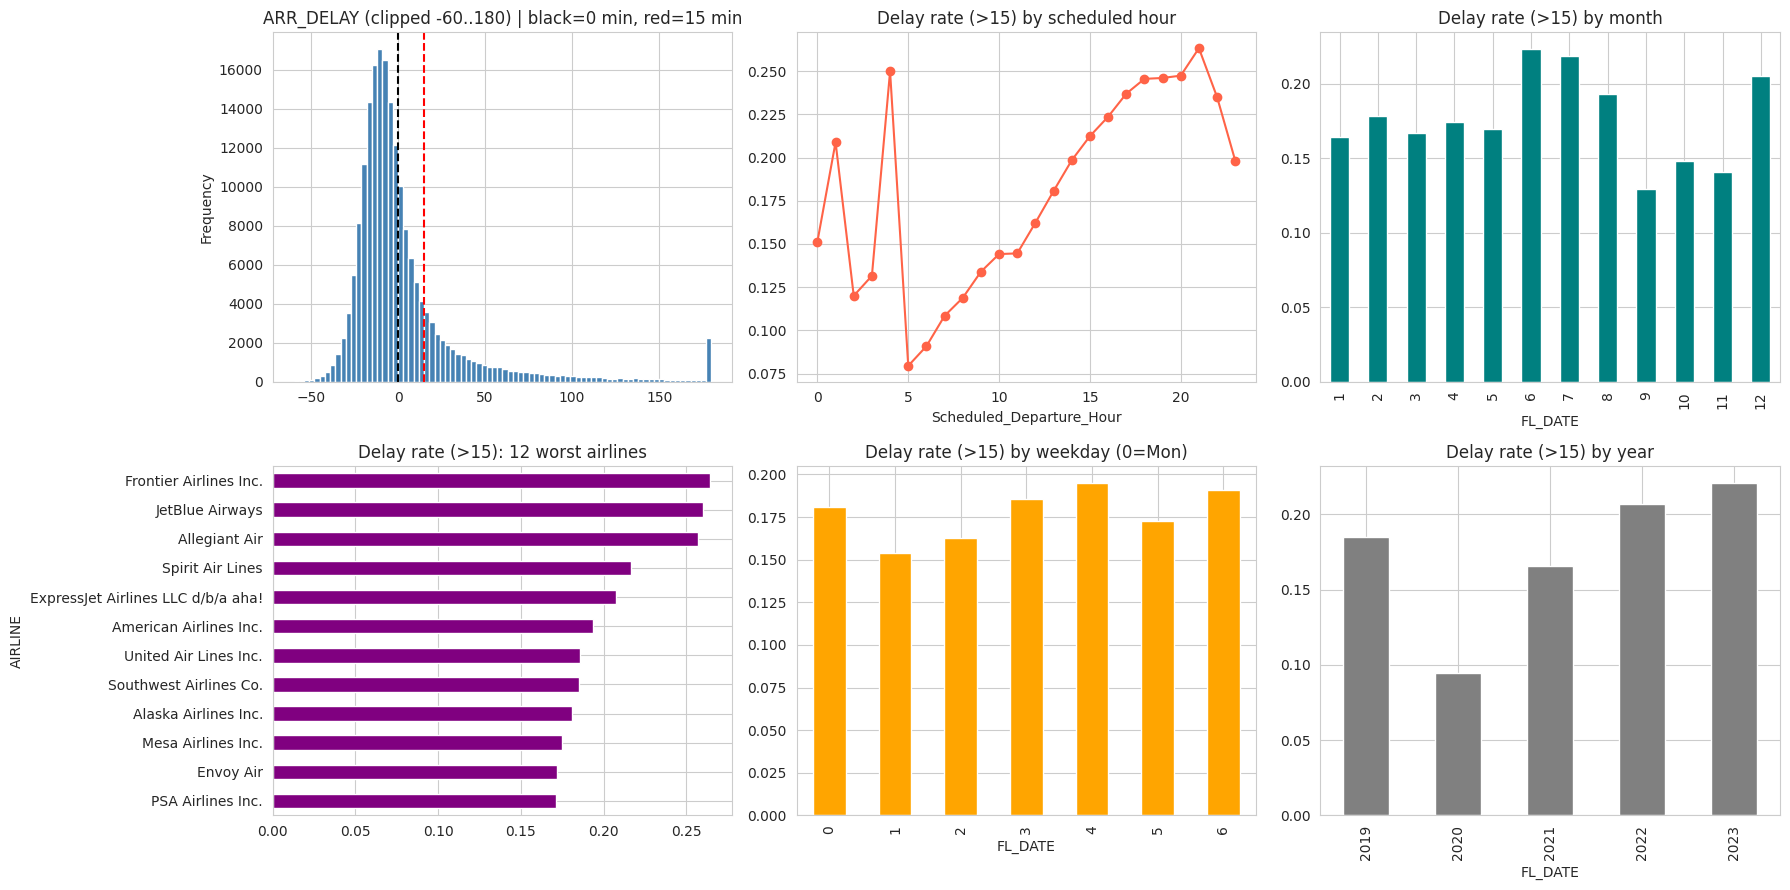

INSIGHTS:
 • Delay rate din ke saath barhta hai (cascading delays) -> hour ek useful feature hai.
 • Month / weekday / year ka asar hai -> paper in ko use hi nahi karta (FL_DATE drop) = missed information.
 • Delay distribution right-skewed hai: zyada flights thori jaldi/on-time, kuch bohat late.


In [20]:
df['late15'] = (df['ARR_DELAY'] > 15).astype(int)
df['late0']  = (df['ARR_DELAY'] > 0).astype(int)
print(f"Delay rate with ARR_DELAY > 15 min : {df['late15'].mean():.1%}")
print(f"Delay rate with ARR_DELAY >  0 min : {df['late0'].mean():.1%}")
print("HOW TO READ: >15 min wala label imbalanced hai (~18% delayed). >0 wala ~39% delayed.\n")

fig, ax = plt.subplots(2, 3, figsize=(18, 9))
df['ARR_DELAY'].clip(-60, 180).plot(kind='hist', bins=80, ax=ax[0,0], color='steelblue')
ax[0,0].axvline(0, color='k', ls='--'); ax[0,0].axvline(15, color='red', ls='--')
ax[0,0].set_title('ARR_DELAY (clipped -60..180) | black=0 min, red=15 min')
df.groupby('Scheduled_Departure_Hour')['late15'].mean().plot(ax=ax[0,1], marker='o', color='tomato')
ax[0,1].set_title('Delay rate (>15) by scheduled hour')
df.groupby(df['FL_DATE'].dt.month)['late15'].mean().plot(kind='bar', ax=ax[0,2], color='teal')
ax[0,2].set_title('Delay rate (>15) by month')
df.groupby('AIRLINE')['late15'].mean().sort_values().tail(12).plot(kind='barh', ax=ax[1,0], color='purple')
ax[1,0].set_title('Delay rate (>15): 12 worst airlines')
df.groupby(df['FL_DATE'].dt.dayofweek)['late15'].mean().plot(kind='bar', ax=ax[1,1], color='orange')
ax[1,1].set_title('Delay rate (>15) by weekday (0=Mon)')
df.groupby(df['FL_DATE'].dt.year)['late15'].mean().plot(kind='bar', ax=ax[1,2], color='gray')
ax[1,2].set_title('Delay rate (>15) by year')
plt.tight_layout(); plt.show()

print("INSIGHTS:")
print(" • Delay rate din ke saath barhta hai (cascading delays) -> hour ek useful feature hai.")
print(" • Month / weekday / year ka asar hai -> paper in ko use hi nahi karta (FL_DATE drop) = missed information.")
print(" • Delay distribution right-skewed hai: zyada flights thori jaldi/on-time, kuch bohat late.")

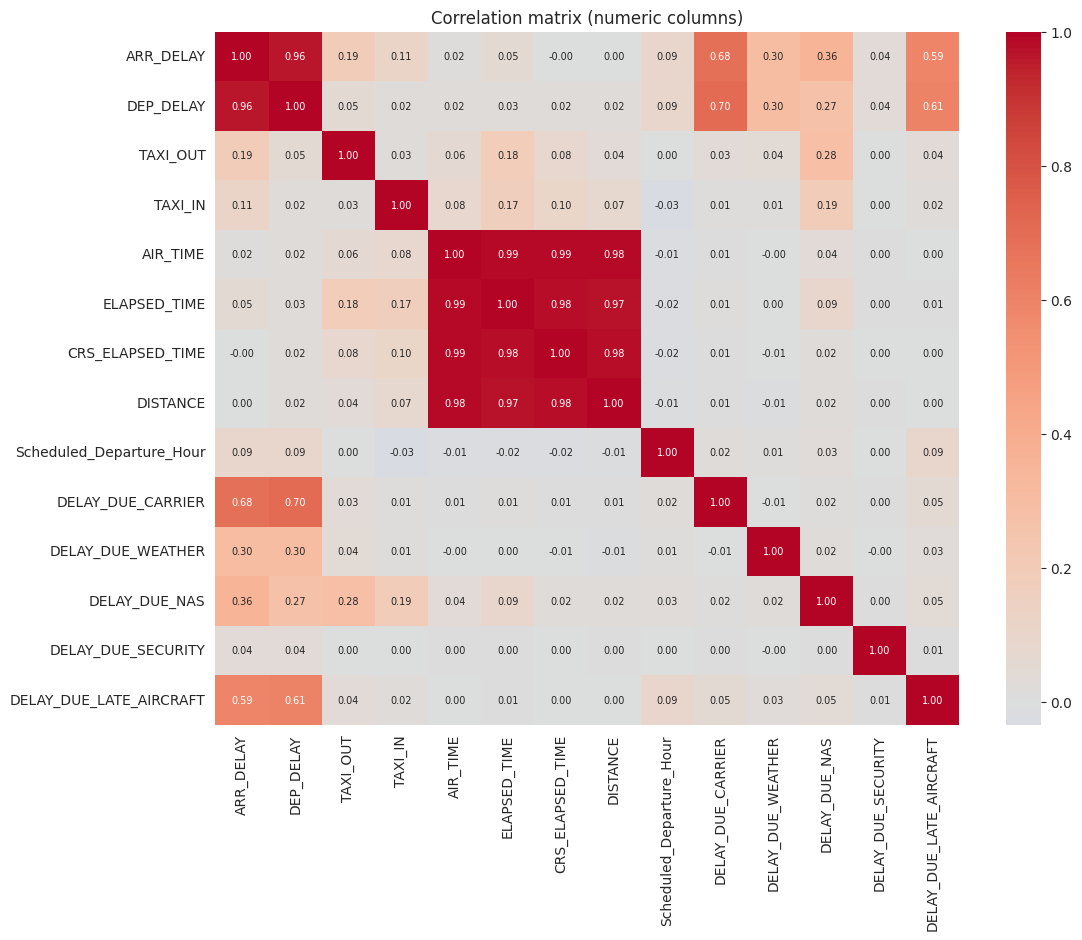

|correlation| with ARR_DELAY (sorted):


,|corr|
DEP_DELAY,0.965
DELAY_DUE_CARRIER,0.683
DELAY_DUE_LATE_AIRCRAFT,0.592
late15,0.591
DELAY_DUE_NAS,0.357
DELAY_DUE_WEATHER,0.298
TAXI_OUT,0.191
TAXI_IN,0.113
Scheduled_Departure_Hour,0.091
ELAPSED_TIME,0.049


HOW TO READ:
 • DELAY_DUE_* aur DEP_DELAY ka ARR_DELAY se corr bohat high hai — ye wo cheezein hain jo flight ke DAURAN/BAAD pata chalti hain => DATA LEAKAGE.
 • CRS_ELAPSED_TIME, ELAPSED_TIME, DISTANCE ek dusre se ~0.97+ correlated hain (multicollinearity).
   Paper 'correlation analysis' ka zikr karta hai magar final mein 'manually selected features' use karta hai (Sec. V-C) aur teeno rakhta hai — isliye replication mein hum bhi teeno rakhte hain.
   Correlation filter threshold paper mein diya hi nahi.


In [21]:
num_for_corr = ['ARR_DELAY', 'DEP_DELAY', 'TAXI_OUT', 'TAXI_IN', 'AIR_TIME', 'ELAPSED_TIME', 'CRS_ELAPSED_TIME',
                'DISTANCE', 'Scheduled_Departure_Hour'] + cause_cols
corr = df[num_for_corr].corr()
plt.figure(figsize=(12, 9)); sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, annot_kws={'size': 7})
plt.title('Correlation matrix (numeric columns)'); plt.show()

c = df[num_for_corr + ['late15']].corr()['ARR_DELAY'].drop('ARR_DELAY').abs().sort_values(ascending=False)
print("|correlation| with ARR_DELAY (sorted):"); display(c.round(3).to_frame('|corr|'))
print("HOW TO READ:")
print(" • DELAY_DUE_* aur DEP_DELAY ka ARR_DELAY se corr bohat high hai — ye wo cheezein hain jo flight ke DAURAN/BAAD pata chalti hain => DATA LEAKAGE.")
print(" • CRS_ELAPSED_TIME, ELAPSED_TIME, DISTANCE ek dusre se ~0.97+ correlated hain (multicollinearity).")
print("   Paper 'correlation analysis' ka zikr karta hai magar final mein 'manually selected features' use karta hai (Sec. V-C) aur teeno rakhta hai — isliye replication mein hum bhi teeno rakhte hain.")
print("   Correlation filter threshold paper mein diya hi nahi.")

# Part 4 — Feature Selection (kya hata, kya rakha, kyun)
Paper Sec. V-C: 4 methods *investigate* kiye (correlation, tree importance, RFE, manual) lekin likha hai: **"In this paper, we have manually selected features"**. To replication = **manual**.

In [22]:
FEATURE_TABLE = pd.DataFrame([
 # column, action, reason, paper reference
 ('FL_DATE',            'DROP', 'Paper: "irrelevant to predicting delays" (Listing 4 mein bhi drop)', '🟢 V-C4 + Listing 4'),
 ('FL_NUMBER',          'DROP', 'Paper: irrelevant (high-cardinality ID)', '🟢 V-C4'),
 ('CANCELLATION_CODE',  'DROP', 'Paper: irrelevant (cancelled flights pehle hi hata di)', '🟢 V-C4'),
 ('DEP_TIME',           'DROP', 'Actual departure time = strong leakage', '🟢 V-C4'),
 ('ARR_TIME',           'DROP', 'Actual arrival time = leakage', '🟢 V-C4'),
 ('WHEELS_OFF',         'DROP', 'Actual takeoff time = leakage', '🟢 V-C4'),
 ('WHEELS_ON, TAXI_OUT, TAXI_IN, AIR_TIME, CRS_ARR_TIME', 'DROP', 'Same family as WHEELS_OFF (post-departure timing); paper ne sab list nahi kiye', '🟡 same logic as paper'),
 ('DELAY_DUE_* (5 cols)', 'DROP', 'Delay ki wajah = delay ka natija (pure leakage). Paper ne impute kiya (V-B1) magar X mein nahi rakh sakte warna ~100% accuracy', '🟡 implied by paper'),
 ('ARR_DELAY, CANCELLED, DIVERTED', 'DROP', 'Target ka source / already filtered', '🟢 Listing 4'),
 ('AIRLINE_DOT, DOT_CODE, ORIGIN_CITY, DEST_CITY', 'DROP', 'Duplicate of AIRLINE / AIRLINE_CODE / ORIGIN / DEST', '🟡 ASSUMED'),
 ('CRS_DEP_TIME',       'DROP', 'Replaced by Scheduled_Departure_Hour', '🟡 ASSUMED'),
 ('AIRLINE, AIRLINE_CODE, ORIGIN, DEST, Time_of_Day', 'KEEP (one-hot)', 'Categorical features', '🟢 Listing 2'),
 ('CRS_ELAPSED_TIME, DISTANCE, Scheduled_Departure_Hour', 'KEEP (scaled)', 'Numeric features', '🟢 Listing 3'),
 ('ELAPSED_TIME',       'KEEP ⚠️ (leaky)', 'Paper rakhta hai (Listing 3). Ye ACTUAL flight duration hai = flight ke baad pata chalta hai. Improvement phase mein hataenge.', '🟢 Listing 3 / 🔴 flagged'),
 ('DEP_DELAY',          'UNKNOWN in paper', 'Paper ne explicitly na rakha na hataya. Isko Part 6 ke grid mein dono tarah test karte hain.', '❓ ambiguous'),
], columns=['Column(s)', 'Action', 'Reason', 'Reference'])
pd.set_option('display.max_colwidth', 120)
display(FEATURE_TABLE)

PAPER_CAT = ['AIRLINE', 'AIRLINE_CODE', 'ORIGIN', 'DEST', 'Time_of_Day']
PAPER_NUM = ['CRS_ELAPSED_TIME', 'ELAPSED_TIME', 'DISTANCE', 'Scheduled_Departure_Hour']
print("\nCardinality of categorical features (one-hot ke baad kitne columns banenge):")
print({c: df[c].nunique() for c in PAPER_CAT})
print("Note: AIRLINE aur AIRLINE_CODE 1-to-1 hain (redundant) — paper dono rakhta hai, hum bhi (replication).")

,Column(s),Action,Reason,Reference
0,FL_DATE,DROP,"Paper: ""irrelevant to predicting delays"" (Listing 4 mein bhi drop)",🟢 V-C4 + Listing 4
1,FL_NUMBER,DROP,Paper: irrelevant (high-cardinality ID),🟢 V-C4
2,CANCELLATION_CODE,DROP,Paper: irrelevant (cancelled flights pehle hi hata di),🟢 V-C4
3,DEP_TIME,DROP,Actual departure time = strong leakage,🟢 V-C4
4,ARR_TIME,DROP,Actual arrival time = leakage,🟢 V-C4
5,WHEELS_OFF,DROP,Actual takeoff time = leakage,🟢 V-C4
6,"WHEELS_ON, TAXI_OUT, TAXI_IN, AIR_TIME, CRS_ARR_TIME",DROP,Same family as WHEELS_OFF (post-departure timing); paper ne sab list nahi kiye,🟡 same logic as paper
7,DELAY_DUE_* (5 cols),DROP,Delay ki wajah = delay ka natija (pure leakage). Paper ne impute kiya (V-B1) magar X mein nahi rakh sakte warna ~100...,🟡 implied by paper
8,"ARR_DELAY, CANCELLED, DIVERTED",DROP,Target ka source / already filtered,🟢 Listing 4
9,"AIRLINE_DOT, DOT_CODE, ORIGIN_CITY, DEST_CITY",DROP,Duplicate of AIRLINE / AIRLINE_CODE / ORIGIN / DEST,🟡 ASSUMED



Cardinality of categorical features (one-hot ke baad kitne columns banenge):
{'AIRLINE': 18, 'AIRLINE_CODE': 18, 'ORIGIN': 378, 'DEST': 377, 'Time_of_Day': 4}
Note: AIRLINE aur AIRLINE_CODE 1-to-1 hain (redundant) — paper dono rakhta hai, hum bhi (replication).


# Part 5 — Paper ke numbers ka audit (reverse-engineering)
Agar ek hi test set par sab models evaluate hue hon, to **Accuracy, Precision, Recall se test-set ka delayed % (prevalence π) nikala ja sakta hai:**

`FP = Recall·π·(1/Precision − 1)`, `FN = (1−Recall)·π`, `Error = 1 − Accuracy = FP + FN`  ⇒  **π = (1−Acc) / (Recall·(1/Prec −1) + (1−Recall))**

Ye hume batata hai ke paper ka asli label kya tha.

In [23]:
PAPER_ALL = {  # paper ki saari tables (I-VIII) — sirf audit ke liye
 'Logistic Reg.':(.850,.791,.812,.801), 'Multi-Logistic':(.863,.813,.824,.811), 'CNN':(.860,.801,.982,.880),
 'RNN':(.854,.821,.989,.901), 'Random Forest':(.872,.831,.845,.838), 'XGBoost':(.883,.842,.865,.853),
 'LightGBM':(.880,.840,.860,.850), 'CatBoost':(.879,.839,.858,.848)}
rows = []
for k, (A, P, R, F) in PAPER_ALL.items():
    pi = (1 - A) / (R * (1/P - 1) + (1 - R))
    rows.append({'Model': k, 'Accuracy': A, 'Precision': P, 'Recall': R, 'F1 (paper)': F,
                 'F1 (recomputed)': round(2*P*R/(P+R), 3), 'Implied delayed % in test': round(pi*100, 1)})
audit = pd.DataFrame(rows); display(audit)
print(f"Our data:  ARR_DELAY > 15  => {df['late15'].mean():.1%} delayed   |   ARR_DELAY > 0 => {df['late0'].mean():.1%} delayed\n")
print("FINDINGS:")
print(" 1) LR, MLR, RF, XGB, LGBM, CatBoost sab ~37-39% delayed imply karte hain => paper ka asli label ~ 'ARR_DELAY > 0' lagta hai,")
print("    jabke text likhta hai '>15 minutes' (>15 par sirf ~18% delayed hote). TEXT aur NUMBERS mein contradiction.")
print(" 2) CNN implies ~53% aur RNN ~64% delayed => same test set par ye numbers ho hi nahi sakte. Ya to CNN/RNN alag split/label par train hue,")
print("    ya tables galat hain. Isliye CNN/RNN ka recall 0.98+ EXACTLY reproduce hona unlikely hai (aur 'high recall' shayad class-prior ka asar hai).")
print(" 3) Paper ka abstract kehta hai CNN/RNN best hain, magar XGBoost ki ACCURACY (0.883) sabse zyada hai. Best kaun hai = metric par depend karta hai.")
print(" 4) Paper kehta hai 'RF metrics RNN ke identical hain' — table mein identical nahi (0.838 vs 0.901 F1). Text-table mismatch.")
print(" 5) Paper 'K-cross fold' likhta hai magar sirf single 80/20 split use hota hai (Listing 4).")

,Model,Accuracy,Precision,Recall,F1 (paper),F1 (recomputed),Implied delayed % in test
0,Logistic Reg.,0.850,0.791,0.812,0.801,0.801,37.3
1,Multi-Logistic,0.863,0.813,0.824,0.811,0.818,37.5
2,CNN,0.860,0.801,0.982,0.880,0.882,53.4
3,RNN,0.854,0.821,0.989,0.901,0.897,64.4
4,Random Forest,0.872,0.831,0.845,0.838,0.838,39.2
5,XGBoost,0.883,0.842,0.865,0.853,0.853,39.4
6,LightGBM,0.880,0.840,0.860,0.850,0.850,39.5
7,CatBoost,0.879,0.839,0.858,0.848,0.848,39.5


Our data:  ARR_DELAY > 15  => 17.8% delayed   |   ARR_DELAY > 0 => 33.8% delayed

FINDINGS:
 1) LR, MLR, RF, XGB, LGBM, CatBoost sab ~37-39% delayed imply karte hain => paper ka asli label ~ 'ARR_DELAY > 0' lagta hai,
    jabke text likhta hai '>15 minutes' (>15 par sirf ~18% delayed hote). TEXT aur NUMBERS mein contradiction.
 2) CNN implies ~53% aur RNN ~64% delayed => same test set par ye numbers ho hi nahi sakte. Ya to CNN/RNN alag split/label par train hue,
    ya tables galat hain. Isliye CNN/RNN ka recall 0.98+ EXACTLY reproduce hona unlikely hai (aur 'high recall' shayad class-prior ka asar hai).
 3) Paper ka abstract kehta hai CNN/RNN best hain, magar XGBoost ki ACCURACY (0.883) sabse zyada hai. Best kaun hai = metric par depend karta hai.
 4) Paper kehta hai 'RF metrics RNN ke identical hain' — table mein identical nahi (0.838 vs 0.901 F1). Text-table mismatch.
 5) Paper 'K-cross fold' likhta hai magar sirf single 80/20 split use hota hai (Listing 4).


# Part 6 — Replication
## 6.1 Matrix builder (paper ka exact pipeline)
- 🟢 One-hot: `pd.get_dummies(..., drop_first=True)` (Listing 2)
- 🟢 `StandardScaler` on CRS_ELAPSED_TIME, ELAPSED_TIME, DISTANCE, Scheduled_Departure_Hour (Listing 3). *(Text mein "Min-Max" likha hai magar code StandardScaler — humne code follow kiya.)*
- 🟢 Scaler **split se pehle** fit hota hai (Listing 3 > Listing 4 ke order se) — ye mild data leakage hai, replication mein `scale_before_split=True` rakha hai, improvement mein theek karenge.
- 🟢 80/20 split, `random_state=42` (Listing 4), 🟡 stratify nahi (paper mein nahi).

In [24]:
def build_xy(data, target_min, keep_dep_delay=False, drop_num=(), scale_before_split=True):
    """Paper-style feature matrix. target = ARR_DELAY > target_min."""
    num = [c for c in PAPER_NUM if c not in drop_num] + (['DEP_DELAY'] if keep_dep_delay else [])
    y = (data['ARR_DELAY'] > target_min).astype(int)
    X = pd.get_dummies(data[PAPER_CAT + num], columns=PAPER_CAT, drop_first=True, dtype=np.uint8)
    sc = StandardScaler()
    if scale_before_split:
        X[num] = sc.fit_transform(X[num])
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=SEED)
    if not scale_before_split:
        Xtr = Xtr.copy(); Xte = Xte.copy()
        Xtr[num] = sc.fit_transform(Xtr[num]); Xte[num] = sc.transform(Xte[num])
    return Xtr.astype('float32'), Xte.astype('float32'), ytr, yte, num

RESULTS = []
def evaluate(phase, name, y_true, y_prob, thr=0.5, secs=None, show_cm=True, note=''):
    y_pred = (y_prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    # ROC-AUC undefined hota hai agar test set mein sirf ek class ho.
    roc = roc_auc_score(y_true, y_prob) if len(np.unique(y_true)) == 2 else np.nan
    pr = average_precision_score(y_true, y_prob) if len(np.unique(y_true)) == 2 else np.nan
    r = {'Phase': phase, 'Model': name, 'Threshold': round(float(thr), 3),
         'Accuracy': accuracy_score(y_true, y_pred), 'Precision': precision_score(y_true, y_pred, zero_division=0),
         'Recall': recall_score(y_true, y_pred, zero_division=0), 'F1': f1_score(y_true, y_pred, zero_division=0),
         'ROC-AUC': roc, 'PR-AUC': pr,
         'Delayed % in test': float(np.mean(y_true))*100, 'Train sec': secs, 'Note': note}
    RESULTS.append(r)
    print(f"[{phase}] {name}  (decision threshold = {thr:.2f})")
    print(f"  Accuracy {r['Accuracy']:.3f} | Precision {r['Precision']:.3f} | Recall {r['Recall']:.3f} | F1 {r['F1']:.3f} | ROC-AUC {r['ROC-AUC']:.3f} | PR-AUC {r['PR-AUC']:.3f}")
    if show_cm:
        print(f"  Test flights: {len(y_true):,}  ({np.mean(y_true):.1%} actually delayed)")
        print(f"   ✔ Correctly said ON-TIME : {tn:,}   (True Negative)")
        print(f"   ✘ False alarm (said LATE, was on-time): {fp:,}   (False Positive)  -> hurts Precision")
        print(f"   ✘ Missed delay (said ON-TIME, was late): {fn:,}   (False Negative) -> hurts Recall")
        print(f"   ✔ Caught delays          : {tp:,}   (True Positive)")
        print(f"  Precision = of flights we called LATE, {r['Precision']:.1%} really were. Recall = of all really-late flights, we caught {r['Recall']:.1%}.")
        print(f"  Baseline: always predicting 'delayed' gives Recall=100%, Precision={np.mean(y_true):.1%}. So metrics ko prevalence ke saath compare karo.")
    return r

def paper_dist(r, paper_row):
    return np.mean([abs(r[k] - paper_row[k]) for k in ['Accuracy', 'Precision', 'Recall', 'F1']])

def make_xgb(n=300):
    from xgboost import XGBClassifier
    common = dict(n_estimators=n, eval_metric='logloss',
                  random_state=SEED, n_jobs=-1)
    # XGBoost 2.x supports device=...; older versions may not.
    try:
        return XGBClassifier(**common, tree_method='hist',
                             device='cuda' if HAS_GPU else 'cpu')
    except TypeError:
        return XGBClassifier(**common,
                             tree_method='gpu_hist' if HAS_GPU else 'hist')
print("helpers ready")

helpers ready


## 6.2 Paper ambiguity → grid search on XGBoost
Paper ke 2 cheezein ambiguous hain: **label threshold** (text: >15, numbers: ~>0) aur **DEP_DELAY use hua ya nahi**.
XGBoost ko 4 combinations par chalate hain aur dekhte hain ke kaun paper ki XGBoost row (A .883 / P .842 / R .865 / F1 .853) ke sabse qareeb hai. Ye "reverse-engineering" hai — isliye honest tarika hai ke hum config ko paper ke numbers se choose kar rahe hain, aur ye baat report mein likhni chahiye.

In [25]:
grid_rows = []
for tmin in [15, 0]:
    for keep_dep in [False, True]:
        t0 = time.time()
        Xtr, Xte, ytr, yte, _ = build_xy(df, tmin, keep_dep)
        m = make_xgb(200); m.fit(Xtr, ytr)
        p = m.predict_proba(Xte)[:, 1]; yp = (p >= .5).astype(int)
        r = {'ARR_DELAY >': tmin, 'DEP_DELAY used': keep_dep, 'Delayed % (test)': round(yte.mean()*100, 1),
             'Accuracy': accuracy_score(yte, yp), 'Precision': precision_score(yte, yp, zero_division=0),
             'Recall': recall_score(yte, yp, zero_division=0), 'F1': f1_score(yte, yp, zero_division=0)}
        r['Avg |diff| vs paper XGB'] = paper_dist(r, PAPER.loc['XGBoost'])
        grid_rows.append(r)
        print(f"done target>{tmin}, DEP_DELAY={keep_dep}  ({time.time()-t0:.0f}s)")
        del Xtr, Xte, m; gc.collect()
grid = pd.DataFrame(grid_rows).round(3).sort_values('Avg |diff| vs paper XGB')
print("\nPaper XGBoost row:", PAPER.loc['XGBoost'].to_dict())
display(grid)
best = grid.iloc[0]
REPL_TARGET_MIN = int(best['ARR_DELAY >']); REPL_KEEP_DEP = bool(best['DEP_DELAY used'])
print(f"\n==> CLOSEST CONFIG: label = ARR_DELAY > {REPL_TARGET_MIN}, DEP_DELAY used = {REPL_KEEP_DEP}")
print("HOW TO READ: jis row ka last column sabse chhota hai wo paper ke sabse qareeb hai. Agar sab rows door hon (>0.03) to paper ke hidden steps hain jo text mein nahi.")

done target>15, DEP_DELAY=False  (43s)
done target>15, DEP_DELAY=True  (63s)
done target>0, DEP_DELAY=False  (49s)
done target>0, DEP_DELAY=True  (59s)

Paper XGBoost row: {'Accuracy': 0.883, 'Precision': 0.842, 'Recall': 0.865, 'F1': 0.853}


,ARR_DELAY >,DEP_DELAY used,Delayed % (test),Accuracy,Precision,Recall,F1,Avg |diff| vs paper XGB
1,15,True,17.8,0.991,0.980,0.970,0.975,0.118
3,0,True,33.6,0.987,0.985,0.978,0.981,0.122
2,0,False,33.6,0.791,0.807,0.496,0.614,0.184
0,15,False,17.8,0.852,0.781,0.233,0.359,0.305



==> CLOSEST CONFIG: label = ARR_DELAY > 15, DEP_DELAY used = True
HOW TO READ: jis row ka last column sabse chhota hai wo paper ke sabse qareeb hai. Agar sab rows door hon (>0.03) to paper ke hidden steps hain jo text mein nahi.


## 6.3 Replication run: XGBoost, CNN, RNN (closest config par)
Architectures paper mein detail se nahi diye. 🟢 Jo paper kehta hai: CNN = Conv + Pooling + Fully-connected + ReLU + Dropout (TensorFlow); RNN = LSTM + Dense (TensorFlow). 🟡 Layer sizes humari assumption. Hyperparameter tuning paper ne **nahi** ki (future work), isliye XGBoost default-ish settings.

In [26]:
Xtr, Xte, ytr, yte, num_cols = build_xy(df, REPL_TARGET_MIN, REPL_KEEP_DEP)
print(f"Train {Xtr.shape}  Test {Xte.shape}  | features after one-hot: {Xtr.shape[1]}")
print(f"Delayed % -> train {ytr.mean():.1%}, test {yte.mean():.1%}")

t0 = time.time(); xgb_r = make_xgb(300); xgb_r.fit(Xtr, ytr); t_xgb = time.time() - t0
p_xgb_r = xgb_r.predict_proba(Xte)[:, 1]
evaluate('Replication', 'XGBoost', yte.values, p_xgb_r, secs=t_xgb)

Train (155123, 795)  Test (38781, 795)  | features after one-hot: 795
Delayed % -> train 17.8%, test 17.8%
[Replication] XGBoost  (decision threshold = 0.50)
  Accuracy 0.991 | Precision 0.980 | Recall 0.970 | F1 0.975 | ROC-AUC 1.000 | PR-AUC 0.998
  Test flights: 38,781  (17.8% actually delayed)
   ✔ Correctly said ON-TIME : 31,732   (True Negative)
   ✘ False alarm (said LATE, was on-time): 139   (False Positive)  -> hurts Precision
   ✘ Missed delay (said ON-TIME, was late): 204   (False Negative) -> hurts Recall
   ✔ Caught delays          : 6,706   (True Positive)
  Precision = of flights we called LATE, 98.0% really were. Recall = of all really-late flights, we caught 97.0%.
  Baseline: always predicting 'delayed' gives Recall=100%, Precision=17.8%. So metrics ko prevalence ke saath compare karo.


{'Phase': 'Replication',
 'Model': 'XGBoost',
 'Threshold': 0.5,
 'Accuracy': 0.9911554627265929,
 'Precision': 0.9796932067202337,
 'Recall': 0.9704775687409551,
 'F1': 0.9750636132315522,
 'ROC-AUC': np.float64(0.999568809429438),
 'PR-AUC': np.float64(0.9980425189515586),
 'Delayed % in test': 17.81800366158686,
 'Train sec': 84.66132640838623,
 'Note': ''}

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
tf.keras.utils.set_random_seed(SEED)
n_feat = Xtr.shape[1]

def fit_dl(model, Xa, ya, Xb, epochs=10):
    es = callbacks.EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    t0 = time.time()
    h = model.fit(Xa, ya, epochs=epochs, batch_size=512, validation_split=0.1, callbacks=[es], verbose=2)
    return model.predict(Xb, batch_size=2048, verbose=0).ravel(), time.time() - t0, h

cnn = models.Sequential([layers.Input(shape=(n_feat, 1)),
    layers.Conv1D(32, 3, activation='relu'), layers.MaxPooling1D(2),
    layers.Conv1D(64, 3, activation='relu'), layers.MaxPooling1D(2),
    layers.Flatten(), layers.Dense(64, activation='relu'), layers.Dropout(0.3),
    layers.Dense(1, activation='sigmoid')])
print("=== CNN training (har epoch ke baad val_loss dekho; EarlyStopping best weights restore karti hai) ===")
p_cnn_r, t_cnn, _ = fit_dl(cnn, Xtr.values.reshape(-1, n_feat, 1), ytr.values, Xte.values.reshape(-1, n_feat, 1))
evaluate('Replication', 'CNN', yte.values, p_cnn_r, secs=t_cnn)

=== CNN training (har epoch ke baad val_loss dekho; EarlyStopping best weights restore karti hai) ===
Epoch 1/10
273/273 - 174s - 639ms/step - accuracy: 0.9177 - loss: 0.2231 - val_accuracy: 0.9520 - val_loss: 0.1200
Epoch 2/10
273/273 - 193s - 706ms/step - accuracy: 0.9592 - loss: 0.1008 - val_accuracy: 0.9695 - val_loss: 0.0747
Epoch 3/10
273/273 - 208s - 761ms/step - accuracy: 0.9714 - loss: 0.0712 - val_accuracy: 0.9767 - val_loss: 0.0586
Epoch 4/10


In [ ]:
rnn = models.Sequential([layers.Input(shape=(1, n_feat)),
    layers.LSTM(64), layers.Dropout(0.3), layers.Dense(32, activation='relu'),
    layers.Dense(1, activation='sigmoid')])
print("=== RNN (LSTM) training ===")
print("NOTE: tabular row = 1 time-step, to LSTM ke paas 'sequence' hai hi nahi (seq length = 1). Ye paper ka literal setup hai; weakness Part 7 mein discuss hogi.")
p_rnn_r, t_rnn, _ = fit_dl(rnn, Xtr.values.reshape(-1, 1, n_feat), ytr.values, Xte.values.reshape(-1, 1, n_feat))
evaluate('Replication', 'RNN (LSTM)', yte.values, p_rnn_r, secs=t_rnn)

In [ ]:
rep = pd.DataFrame([r for r in RESULTS if r['Phase'] == 'Replication']).set_index('Model')
rep = rep.rename(index={'RNN (LSTM)': 'RNN (LSTM)'})
cmp_rows = []
for m in ['XGBoost', 'CNN', 'RNN (LSTM)']:
    for k in ['Accuracy', 'Precision', 'Recall', 'F1']:
        d = rep.loc[m, k] - PAPER.loc[m, k]
        verdict = 'MATCH (<=0.01)' if abs(d) <= .01 else ('CLOSE (<=0.03)' if abs(d) <= .03 else 'DIFFERENT')
        cmp_rows.append({'Model': m, 'Metric': k, 'Paper': PAPER.loc[m, k], 'Ours': round(rep.loc[m, k], 3),
                         'Diff (ours-paper)': round(d, 3), 'Verdict': verdict})
cmp_df = pd.DataFrame(cmp_rows); display(cmp_df)
print("Delayed % in OUR test set:", round(rep['Delayed % in test'].iloc[0], 1))
print("Paper-implied delayed %  : XGB 39.4 | CNN 53.4 | RNN 64.4   (Part 5)")
print("\nHOW TO READ THIS TABLE:")
print(" • XGBoost: agar MATCH/CLOSE aaye to paper ka XGB result reproduce ho gaya.")
print(" • CNN/RNN: paper ke recall (0.98+) is liye hard hain ke wo test set ka 53-64% delayed imply karte hain. Agar hamara recall paper se kam aur precision zyada ho, to wo class-prior ka farq hai, model ka nahi.")
print(" • Agar kuch DIFFERENT hai: wo paper ke hidden choices (exact architecture, sample, epochs, threshold) ki wajah se — hum isko 'unreproducible from text alone' likhte hain.")

In [ ]:
# ---- Paper claims "K-fold" — humne bhi check kiya: single split kitna stable hai? ----
print("5-fold Stratified CV on XGBoost (replication config, 200k subsample for speed)")
Xall = pd.concat([Xtr, Xte]); yall = pd.concat([ytr, yte])
idx = np.random.RandomState(SEED).choice(len(Xall), min(200_000, len(Xall)), replace=False)
Xs, ys = Xall.iloc[idx], yall.iloc[idx]
f1s, accs = [], []
for i, (a, b_) in enumerate(StratifiedKFold(5, shuffle=True, random_state=SEED).split(Xs, ys), 1):
    m = make_xgb(150); m.fit(Xs.iloc[a], ys.iloc[a]); yp = m.predict(Xs.iloc[b_])
    f1s.append(f1_score(ys.iloc[b_], yp)); accs.append(accuracy_score(ys.iloc[b_], yp))
    print(f"  fold {i}: acc {accs[-1]:.4f}  F1 {f1s[-1]:.4f}")
print(f"Accuracy {np.mean(accs):.4f} ± {np.std(accs):.4f} | F1 {np.mean(f1s):.4f} ± {np.std(f1s):.4f}")
print("HOW TO READ: ± chhota hai => single 80/20 split theek stable hai; paper ke 3-decimal differences (0.880 vs 0.883) statistically meaningful nahi.")
del Xall, yall, Xs, ys; gc.collect()

In [ ]:
# ---- Replication XGBoost kya seekh raha hai? (leakage ka saboot) ----
imp = pd.Series(xgb_r.feature_importances_, index=Xtr.columns).sort_values(ascending=False).head(15)
plt.figure(figsize=(8, 5)); imp[::-1].plot(kind='barh', color='darkgreen'); plt.title('Top-15 XGBoost feature importances (replication)'); plt.show()
print(imp.round(4).to_frame('importance'))
print("HOW TO READ: agar ELAPSED_TIME (ya DEP_DELAY) top par hai to model flight ke 'baad' ki info se predict kar raha hai — real life mein ye pehle se maloom nahi hoti.")

# Part 7 — Loopholes & Improvements

## Loopholes jo paper mein mile (evidence ke saath)
| # | Loophole | Evidence | Fix (is notebook mein) |
|---|---|---|---|
| L1 | **Text vs numbers mismatch**: label ">15 min" likha, numbers ~>0 imply karte hain | Part 5 | Dono labels report karte hain; main comparison same label par |
| L2 | **CNN/RNN tables same test set par impossible** (implied 53%/64% vs 39%) | Part 5 | Honest reporting; metrics + ROC/PR-AUC (prevalence-independent) |
| L3 | **Leakage**: ELAPSED_TIME (actual duration) feature hai; scaler split se pehle fit | Listing 3-4, importances | ELAPSED_TIME drop; scaler split ke baad |
| L4 | **Random split** — 2019-2023 data (COVID era shift) mein future ki info train mein | Listing 4 | **Time-based split** |
| L5 | **FL_DATE drop** → month/weekday/seasonality ignore | EDA | Calendar features |
| L6 | **~800 one-hot columns** (ORIGIN/DEST) — sparse, CNN ke liye meaningless "spatial" order | Part 4 | Out-of-fold **target encoding** |
| L7 | **RNN with sequence length 1** = sirf ek dense network; "temporal patterns" claim sach nahi | Part 6.3 | Honest label; real sequences ke liye tail-number/airport history chahiye (dataset mein nahi) |
| L8 | **CNN on tabular features**: feature order arbitrary hai, "spatial" locality nahi | Sec. V-D3 | Compare with tabular baseline (XGB) |
| L9 | **Threshold 0.5 fixed**, imbalance handle nahi | Listing code | Validation par threshold tune |
| L10 | **Accuracy / F1 only**, no ROC/PR-AUC, no baseline, no CI, K-fold claim but unused | Sec. V-E | AUCs + baseline + CV |
| L11 | **Weather claim**: text weather use karne ka kehta hai, dataset mein weather columns hain hi nahi | Sec. V-A | Honest note; external weather (NOAA) as future work |
| L12 | **No hyperparameter tuning**, no random seeds/arch details = not reproducible | Sec. VII | Details yahan explicitly diye |

## Improvement ladder (har step ek change, taake pata chale kisne kitna farq daala)
- **I-0** Replication XGB (reference)
- **I-1** `ELAPSED_TIME` hataya (leakage fix, baqi same)
- **I-2** Naye pre-departure features + target encoding (random split)
- **I-3** Time-based split (realistic)
- **I-4** Validation-tuned threshold
- **I-5** CNN / RNN improved features par

In [ ]:
# ---- I-1: leakage fix — ELAPSED_TIME hatao, baqi sab replication jaisa ----
t0 = time.time()
Xtr1, Xte1, ytr1, yte1, _ = build_xy(df, REPL_TARGET_MIN, REPL_KEEP_DEP, drop_num=('ELAPSED_TIME',))
m1 = make_xgb(300); m1.fit(Xtr1, ytr1)
r0 = [r for r in RESULTS if r['Phase'] == 'Replication' and r['Model'] == 'XGBoost'][0]
r1 = evaluate('I-1 no ELAPSED_TIME', 'XGBoost', yte1.values, m1.predict_proba(Xte1)[:, 1], secs=time.time()-t0)
print(f"\nCHANGE vs replication: Accuracy {r1['Accuracy']-r0['Accuracy']:+.3f} | F1 {r1['F1']-r0['F1']:+.3f} | ROC-AUC {r1['ROC-AUC']-r0['ROC-AUC']:+.3f}")
print("HOW TO READ: bara drop = ELAPSED_TIME leakage tha (paper ke numbers is feature ki wajah se inflated). Chhota drop = model dusre features se kaam chala raha tha.")
del Xtr1, Xte1, m1; gc.collect()

### I-2 / I-3 — Naye features (sirf wo jo **scheduled departure se pehle** maloom hon)
| Feature | Kyun | Leakage? |
|---|---|---|
| month, weekday, weekend | seasonality (EDA mein dikha) | ❌ schedule se pata |
| hour sin/cos | 23:00 aur 00:00 paas hain — circular | ❌ |
| scheduled arrival hour | red-eye / late-night flights | ❌ |
| `sched_load` = scheduled flights from same origin in same date+hour | airport congestion proxy | ❌ (count of schedule, label nahi) — *sample 1/6 hai to noisy* |
| Target-encoded AIRLINE_CODE, ORIGIN, DEST, ROUTE | 800 one-hot ki jagah 4 numbers | ✔ **out-of-fold** (train ke andar), test par full-train mapping |

In [ ]:
def build_improved(data, target_min):
    F = pd.DataFrame(index=data.index)
    dt = data['FL_DATE']
    hr = data['Scheduled_Departure_Hour']
    F['dep_hour_sin'] = np.sin(2*np.pi*hr/24); F['dep_hour_cos'] = np.cos(2*np.pi*hr/24)
    F['arr_hour'] = (data['CRS_ARR_TIME'].astype(int)//100).clip(0, 23)
    F['month'] = dt.dt.month; F['dow'] = dt.dt.dayofweek; F['is_weekend'] = (F['dow'] >= 5).astype(int)
    F['CRS_ELAPSED_TIME'] = data['CRS_ELAPSED_TIME']; F['DISTANCE'] = data['DISTANCE']
    key = data['ORIGIN'].astype(str) + '|' + dt.dt.strftime('%Y%m%d') + '|' + hr.astype(str)
    F['sched_load'] = key.map(key.value_counts())
    F['AIRLINE_CODE'] = data['AIRLINE_CODE']; F['ORIGIN'] = data['ORIGIN']; F['DEST'] = data['DEST']
    F['ROUTE'] = data['ORIGIN'].astype(str) + '>' + data['DEST'].astype(str)
    y = (data['ARR_DELAY'] > target_min).astype(int)
    return F, y

TE_COLS = ['AIRLINE_CODE', 'ORIGIN', 'DEST', 'ROUTE']
NUM_IMP = ['dep_hour_sin', 'dep_hour_cos', 'arr_hour', 'month', 'dow', 'is_weekend', 'CRS_ELAPSED_TIME', 'DISTANCE', 'sched_load']

def target_encode(col_train, y_train, smooth=50, folds=5):
    """Out-of-fold smoothed mean encoding: (sum + smooth*prior)/(count + smooth)."""
    prior = y_train.mean(); oof = np.zeros(len(col_train))
    for a, b_ in KFold(folds, shuffle=True, random_state=SEED).split(col_train):
        g = pd.DataFrame({'c': col_train.values[a], 'y': y_train.values[a]}).groupby('c')['y'].agg(['sum', 'count'])
        enc = (g['sum'] + smooth*prior) / (g['count'] + smooth)
        oof[b_] = col_train.iloc[b_].map(enc).fillna(prior).values
    g = pd.DataFrame({'c': col_train.values, 'y': y_train.values}).groupby('c')['y'].agg(['sum', 'count'])
    return oof, (g['sum'] + smooth*prior) / (g['count'] + smooth), prior

def prepare_improved(F, y, tr, others):
    """tr = train indices (positions); others = dict name->positions. Encoders fit ONLY on train."""
    Ftr, ytr_ = F.iloc[tr], y.iloc[tr]
    out = {'train': Ftr[NUM_IMP].copy()}
    maps = {}
    for c in TE_COLS:
        out['train']['te_'+c], maps[c], prior = target_encode(Ftr[c], ytr_)
    for k, ix in others.items():
        o = F.iloc[ix][NUM_IMP].copy()
        for c in TE_COLS: o['te_'+c] = F.iloc[ix][c].map(maps[c]).fillna(prior).values
        out[k] = o
    return {k: v.astype('float32') for k, v in out.items()}

F_imp, y_imp = build_improved(df, REPL_TARGET_MIN)
print("Improved feature matrix:", F_imp.shape, "| label = ARR_DELAY >", REPL_TARGET_MIN)
display(F_imp.head(3))

# ---------- I-2: new features, SAME random 80/20 split as paper ----------
rs = np.random.RandomState(SEED).permutation(len(F_imp)); cut = int(.8*len(rs))
tr_r, te_r = rs[:cut], rs[cut:]
t0 = time.time()
D = prepare_improved(F_imp, y_imp, tr_r, {'test': te_r})
m2 = make_xgb(300); m2.fit(D['train'], y_imp.iloc[tr_r])
r2 = evaluate('I-2 new features (random split)', 'XGBoost', y_imp.iloc[te_r].values, m2.predict_proba(D['test'])[:, 1], secs=time.time()-t0)
print(f"\nCHANGE vs I-1: Accuracy {r2['Accuracy']-r1['Accuracy']:+.3f} | ROC-AUC {r2['ROC-AUC']-r1['ROC-AUC']:+.3f} | features: ~800 -> {D['train'].shape[1]}")
print("HOW TO READ: kam features (ab sirf pre-departure info) mein performance comparable ya behtar = information density badhi, leakage nahi.")

In [ ]:
# ---------- I-3: time-based split (train: earliest 70%, validation: next 10%, test: latest 20%) ----------
order = np.argsort(df['FL_DATE'].to_numpy(), kind='stable')
n = len(order); a, b_ = int(.7*n), int(.8*n)
tr_t, va_t, te_t = order[:a], order[a:b_], order[b_:]
print("Train dates:", df['FL_DATE'].iloc[tr_t].min().date(), '->', df['FL_DATE'].iloc[tr_t].max().date())
print("Val   dates:", df['FL_DATE'].iloc[va_t].min().date(), '->', df['FL_DATE'].iloc[va_t].max().date())
print("Test  dates:", df['FL_DATE'].iloc[te_t].min().date(), '->', df['FL_DATE'].iloc[te_t].max().date())

D3 = prepare_improved(F_imp, y_imp, tr_t, {'val': va_t, 'test': te_t})
y_tr3, y_va3, y_te3 = y_imp.iloc[tr_t], y_imp.iloc[va_t], y_imp.iloc[te_t]
t0 = time.time()
m3 = make_xgb(300); m3.fit(D3['train'], y_tr3); t3 = time.time()-t0
pv3, pt3 = m3.predict_proba(D3['val'])[:, 1], m3.predict_proba(D3['test'])[:, 1]
r3 = evaluate('I-3 time-based split', 'XGBoost', y_te3.values, pt3, secs=t3)
print(f"\nCHANGE vs I-2: Accuracy {r3['Accuracy']-r2['Accuracy']:+.3f} | ROC-AUC {r3['ROC-AUC']-r2['ROC-AUC']:+.3f}")
print("HOW TO READ: ye number real deployment ke zyada qareeb hai (past se train, future par test). Drop = random split ne paper ke result ko optimistic banaya tha.")

In [ ]:
# ---------- I-4: threshold validation set par tune (test par nahi!) ----------
def best_threshold(yv, pv):
    grid_t = np.linspace(0.1, 0.9, 81)
    f1s = [f1_score(yv, (pv >= t).astype(int)) for t in grid_t]
    return grid_t[int(np.argmax(f1s))], max(f1s)
thr, f1v = best_threshold(y_va3.values, pv3)
print(f"Best threshold on VALIDATION = {thr:.2f} (val F1 {f1v:.3f}); default 0.50 tha.")
r4 = evaluate('I-4 tuned threshold', 'XGBoost', y_te3.values, pt3, thr=thr, secs=t3, note='threshold from validation')
print("\nHOW TO READ: threshold sirf validation se choose hua, test ko touch nahi kiya => fair. Threshold badalne se Precision/Recall trade-off badalta hai; ROC-AUC same rehta hai.")

In [ ]:
# ---------- I-5: CNN & RNN on improved (compact) features, time-based split ----------
sc = StandardScaler().fit(D3['train'])            # 🔴 DEVIATION fix: scaler sirf train par fit
S = {k: sc.transform(v).astype('float32') for k, v in D3.items()}
nf = S['train'].shape[1]
print(f"{nf} compact features -> CNN/RNN ab 800 sparse dummies par nahi, dense numeric features par.")

def fit_dl2(model, tr3d, va3d, te3d, epochs=15):
    es = callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='binary_crossentropy')
    t0 = time.time()
    model.fit(tr3d, y_tr3.values, epochs=epochs, batch_size=512, validation_data=(va3d, y_va3.values), callbacks=[es], verbose=2)
    return model.predict(va3d, batch_size=4096, verbose=0).ravel(), model.predict(te3d, batch_size=4096, verbose=0).ravel(), time.time()-t0

tf.keras.utils.set_random_seed(SEED)
cnn2 = models.Sequential([layers.Input(shape=(nf, 1)),
    layers.Conv1D(32, 3, padding='same', activation='relu'), layers.MaxPooling1D(2),
    layers.Conv1D(64, 3, padding='same', activation='relu'), layers.GlobalAveragePooling1D(),
    layers.Dense(64, activation='relu'), layers.Dropout(0.3), layers.Dense(1, activation='sigmoid')])
print("=== improved CNN ===")
pv, pt, t_c = fit_dl2(cnn2, S['train'][..., None], S['val'][..., None], S['test'][..., None])
thr_c, _ = best_threshold(y_va3.values, pv)
evaluate('I-5 improved', 'CNN', y_te3.values, pt, thr=thr_c, secs=t_c, note='tuned thr')

rnn2 = models.Sequential([layers.Input(shape=(nf, 1)),                 # features ko ordered sequence maan kar LSTM (tabular data par honest caveat)
    layers.LSTM(64), layers.Dropout(0.3), layers.Dense(32, activation='relu'), layers.Dense(1, activation='sigmoid')])
print("\n=== improved RNN (LSTM over feature sequence) ===")
pv, pt, t_r = fit_dl2(rnn2, S['train'][..., None], S['val'][..., None], S['test'][..., None])
thr_r, _ = best_threshold(y_va3.values, pv)
evaluate('I-5 improved', 'RNN (LSTM)', y_te3.values, pt, thr=thr_r, secs=t_r, note='tuned thr')
print("\nCAVEAT: tabular features mein natural 'time sequence' nahi hoti. LSTM yahan sirf ek aur function approximator hai — real temporal modelling ke liye tail-number / airport-history sequences chahiye (is dataset mein nahi).")

In [ ]:
# ---------- Optional: A15 (official US DOT 'delayed' = >15 min) label par improved XGBoost ----------
if REPL_TARGET_MIN != 15:
    F15, y15 = build_improved(df, 15)
    D15 = prepare_improved(F15, y15, tr_t, {'val': va_t, 'test': te_t})
    m15 = make_xgb(300); m15.fit(D15['train'], y15.iloc[tr_t])
    pv15, pt15 = m15.predict_proba(D15['val'])[:, 1], m15.predict_proba(D15['test'])[:, 1]
    t15, _ = best_threshold(y15.iloc[va_t].values, pv15)
    evaluate('I-4b label >15 min', 'XGBoost', y15.iloc[te_t].values, pt15, thr=t15, note='official A15 label, tuned thr')
    print("HOW TO READ: ye hard task hai (sirf ~18% delayed). Yahan Accuracy misleading hai (hamesha 'on-time' bolo to ~82%); PR-AUC aur F1 dekho.")

In [ ]:
# ---------- FINAL SUMMARY ----------
final = pd.DataFrame(RESULTS)
cols = ['Phase', 'Model', 'Threshold', 'Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC', 'Delayed % in test', 'Train sec']
print("PAPER:"); display(PAPER)
print("\nALL OUR RESULTS:"); display(final[cols].round(3))

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
lab = final['Phase'].str.slice(0, 22) + '\n' + final['Model']
ax[0].barh(lab, final['F1'], color='steelblue'); ax[0].set_title('F1 (note: label/prevalence phases ke beech alag ho sakta hai)')
ax[1].barh(lab, final['ROC-AUC'], color='darkorange'); ax[1].set_title('ROC-AUC (prevalence-independent)'); ax[1].set_xlim(0.5, 1)
plt.tight_layout(); plt.show()

final.to_csv('all_results.csv', index=False); cleaning_log_df = pd.DataFrame(cleaning_log); cleaning_log_df.to_csv('cleaning_log.csv', index=False)
import joblib; joblib.dump(m3, 'xgb_improved.joblib')
print("Saved: all_results.csv, cleaning_log.csv, xgb_improved.joblib")
print("\nHOW TO READ THE FINAL STORY:")
print(" 1. Replication rows  -> paper ke numbers kitne reproduce hue (Part 6.3 ka Verdict column).")
print(" 2. I-1 row           -> leakage hatane ka asar.")
print(" 3. I-2 / I-3 rows    -> naye features aur realistic split ka asar.")
print(" 4. I-4 / I-5 rows    -> threshold tuning + compact features par NN.")
print(" 5. ROC-AUC / PR-AUC  -> in par models ko compare karo, kyunke Accuracy/F1 label aur prevalence par depend karte hain.")

# Part 8 — NEW INNOVATION: Cancellation Risk, Cause Analysis & Prevention

This module complements (does not replace) the delay model above.

**Two distinct prediction tasks**
1. **Cancellation risk model:** `CANCELLED` (0/1) is the target. Inputs are restricted to schedule, date, airline and route fields intended to be known before departure.
2. **Cancellation cause model:** trained only on already-cancelled flights, with `CANCELLATION_CODE` as the target. The code is a label, never an input to the risk model.

**Official US DOT/BTS cause labels:** A = Air Carrier, B = Extreme Weather, C = National Aviation System (NAS), D = Security. These are broad reporting categories, not detailed root-cause diagnoses.

**Important:** a prediction is a risk estimate, not proof that a flight will cancel. Prevention actions are decision-support suggestions. Safety, weather, security and ATC decisions remain with authorized operational teams. The dataset does not include detailed maintenance logs, crew rosters or live weather observations, so the system cannot diagnose those specific factors unless additional data are connected.


In [ ]:
# ---------- Cancellation module: preserve outcome and cause labels separately ----------
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay,
                             precision_recall_curve, roc_auc_score,
                             average_precision_score, precision_score,
                             recall_score, f1_score, accuracy_score)
import matplotlib.pyplot as plt
import joblib

# Find cancellation-code field without assuming every CSV uses the same spelling.
code_candidates = ['CANCELLATION_CODE', 'CANCELLATION_CODE', 'CANCELATION_CODE', 'CANCELLATIONCODE']
code_col = next((c for c in code_candidates if c in cancel_source.columns), None)
cancel_df = cancel_source.copy()

# Robust target parsing: only explicit 0/1 values are kept.
cancel_df['CANCELLED'] = pd.to_numeric(cancel_df['CANCELLED'], errors='coerce')
cancel_df = cancel_df[cancel_df['CANCELLED'].isin([0, 1])].copy()
cancel_df['CANCELLED'] = cancel_df['CANCELLED'].astype(int)
cancel_df['FL_DATE'] = pd.to_datetime(cancel_df['FL_DATE'], errors='coerce')
cancel_df = cancel_df[cancel_df['FL_DATE'].notna()].copy()

print("CANCELLATION DATA AUDIT")
print("Rows available:", f"{len(cancel_df):,}")
print("Cancellation rate:", f"{cancel_df['CANCELLED'].mean():.2%}")
print(cancel_df['CANCELLED'].value_counts().rename(index={0:'Not cancelled',1:'Cancelled'}))

# ----------------- A. Actual historical cancellation-cause analysis -----------------
CAUSE_MAP = {
    'A': 'Air Carrier',
    'B': 'Extreme Weather',
    'C': 'National Aviation System (NAS)',
    'D': 'Security'
}
cause_counts = None
if code_col is not None:
    cancel_df[code_col] = cancel_df[code_col].astype('string').str.strip().str.upper()
    cause_rows = cancel_df[(cancel_df['CANCELLED'] == 1) & cancel_df[code_col].isin(CAUSE_MAP)].copy()
    if len(cause_rows):
        cause_rows['Cause'] = cause_rows[code_col].map(CAUSE_MAP)
        cause_counts = (cause_rows.groupby(['Cause', code_col]).size()
                        .rename('Cancelled flights').reset_index()
                        .sort_values('Cancelled flights', ascending=False))
        cause_counts['Share of coded cancellations (%)'] = (
            cause_counts['Cancelled flights'] / cause_counts['Cancelled flights'].sum() * 100
        ).round(2)
        print("\\nACTUAL CAUSE DISTRIBUTION IN THIS LOADED DATASET")
        display(cause_counts)
        cause_counts.to_csv('cancellation_cause_analysis.csv', index=False)
        top_cause = cause_counts.iloc[0]
        print(f"Most frequent coded cause in this sample: {top_cause['Cause']} "
              f"({top_cause['Share of coded cancellations (%)']:.1f}% of coded cancellations).")
        plt.figure(figsize=(9, 4))
        plt.bar(cause_counts['Cause'], cause_counts['Cancelled flights'])
        plt.xticks(rotation=20, ha='right')
        plt.ylabel('Number of cancelled flights')
        plt.title('Observed cancellation causes (coded cancellations only)')
        plt.tight_layout()
        plt.show()
    else:
        print("No cancelled rows with recognized A/B/C/D cancellation codes were found.")
else:
    print("CANCELLATION CAUSE ANALYSIS UNAVAILABLE: no CANCELLATION_CODE column in this CSV.")
    print("Do not infer official cancellation causes from delay-cause columns; obtain a dataset with cancellation codes.")

# ----------------- B. Build only pre-departure risk features -----------------
def build_cancellation_features(data):
    X = pd.DataFrame(index=data.index)
    dt = pd.to_datetime(data['FL_DATE'], errors='coerce')
    dep = pd.to_numeric(data['CRS_DEP_TIME'], errors='coerce').fillna(0).astype(int)
    arr = pd.to_numeric(data['CRS_ARR_TIME'], errors='coerce').fillna(0).astype(int)
    dep_hour = (dep // 100).clip(0, 23)
    arr_hour = (arr // 100).clip(0, 23)
    X['month'] = dt.dt.month
    X['day_of_week'] = dt.dt.dayofweek
    X['is_weekend'] = (dt.dt.dayofweek >= 5).astype(int)
    X['dep_hour_sin'] = np.sin(2*np.pi*dep_hour/24)
    X['dep_hour_cos'] = np.cos(2*np.pi*dep_hour/24)
    X['scheduled_arrival_hour'] = arr_hour
    X['CRS_ELAPSED_TIME'] = pd.to_numeric(data['CRS_ELAPSED_TIME'], errors='coerce')
    X['DISTANCE'] = pd.to_numeric(data['DISTANCE'], errors='coerce')
    for c in ['AIRLINE', 'AIRLINE_CODE', 'ORIGIN', 'DEST']:
        if c in data.columns:
            X[c] = data[c].astype('string').fillna('UNKNOWN').astype(str)
    X['ROUTE'] = (data['ORIGIN'].astype('string').fillna('UNK').astype(str) + '>' +
                  data['DEST'].astype('string').fillna('UNK').astype(str))
    return X

X_cancel = build_cancellation_features(cancel_df)
y_cancel = cancel_df['CANCELLED'].astype(int)

# Chronological 70/10/20 split: train on earlier dates, validate/tune on next period,
# and reserve the latest period for final testing.
order_c = np.argsort(cancel_df['FL_DATE'].to_numpy(), kind='stable')
n_c = len(order_c)
i_train, i_val = int(.70*n_c), int(.80*n_c)
idx_train, idx_val, idx_test = order_c[:i_train], order_c[i_train:i_val], order_c[i_val:]
y_train_c, y_val_c, y_test_c = y_cancel.iloc[idx_train], y_cancel.iloc[idx_val], y_cancel.iloc[idx_test]

cat_c = X_cancel.select_dtypes(include=['object', 'string']).columns.tolist()
num_c = [c for c in X_cancel.columns if c not in cat_c]
try:
    ohe_c = OneHotEncoder(handle_unknown='ignore', sparse_output=True)
except TypeError:
    ohe_c = OneHotEncoder(handle_unknown='ignore', sparse=True)

prep_c = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median'))]), num_c),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                      ('onehot', ohe_c)]), cat_c)
], remainder='drop')

n_pos = int(y_train_c.sum())
n_neg = int((y_train_c == 0).sum())
if y_train_c.nunique() < 2:
    raise ValueError("Cancellation risk training partition has only one class. Use a larger/full dataset or inspect date coverage.")
risk_model = Pipeline([
    ('prep', prep_c),
    ('model', make_xgb(250))
])
risk_model.set_params(model__scale_pos_weight=max(1.0, n_neg / max(n_pos, 1)))
risk_model.fit(X_cancel.iloc[idx_train], y_train_c)

p_val_c = risk_model.predict_proba(X_cancel.iloc[idx_val])[:, 1]
p_test_c = risk_model.predict_proba(X_cancel.iloc[idx_test])[:, 1]

# Threshold is selected on validation only, not on the final test.
thr_grid_c = np.linspace(0.05, 0.95, 91)
f1_grid_c = [f1_score(y_val_c, (p_val_c >= t).astype(int), zero_division=0) for t in thr_grid_c]
cancel_threshold = float(thr_grid_c[int(np.argmax(f1_grid_c))])
pred_test_c = (p_test_c >= cancel_threshold).astype(int)

cancel_metrics = pd.DataFrame([{
    'Model': 'XGBoost cancellation risk',
    'Threshold (validation tuned)': cancel_threshold,
    'Accuracy': accuracy_score(y_test_c, pred_test_c),
    'Precision': precision_score(y_test_c, pred_test_c, zero_division=0),
    'Recall': recall_score(y_test_c, pred_test_c, zero_division=0),
    'F1': f1_score(y_test_c, pred_test_c, zero_division=0),
    'ROC-AUC': roc_auc_score(y_test_c, p_test_c) if y_test_c.nunique() == 2 else np.nan,
    'PR-AUC': average_precision_score(y_test_c, p_test_c) if y_test_c.nunique() == 2 else np.nan,
    'Test cancellation rate (%)': y_test_c.mean()*100,
    'Train rows': len(idx_train), 'Validation rows': len(idx_val), 'Test rows': len(idx_test)
}])
print("\\nCANCELLATION RISK MODEL — LATEST 20% CHRONOLOGICAL TEST")
display(cancel_metrics.round(4))
print("Validation-selected threshold:", round(cancel_threshold, 3))
print(classification_report(y_test_c, pred_test_c, target_names=['Not cancelled', 'Cancelled'], zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test_c, pred_test_c,
    display_labels=['Not cancelled', 'Cancelled'], cmap='Blues')
plt.title('Cancellation risk model — chronological test')
plt.tight_layout()
plt.show()
cancel_metrics.to_csv('cancellation_model_metrics.csv', index=False)
joblib.dump(risk_model, 'cancellation_risk_model.joblib')

# ----------------- C. Cancellation cause classifier (cancelled flights only) -----------------
cause_model = None
cause_metrics = None
if code_col is not None:
    known = cancel_df[cancel_df['CANCELLED'].eq(1) & cancel_df[code_col].isin(CAUSE_MAP)].copy()
    known['CAUSE_LABEL'] = known[code_col].map(CAUSE_MAP)
    if len(known) >= 50 and known['CAUSE_LABEL'].nunique() >= 2:
        X_cause = build_cancellation_features(known)
        y_cause = known['CAUSE_LABEL'].astype(str)
        order_k = np.argsort(known['FL_DATE'].to_numpy(), kind='stable')
        nk = len(order_k)
        ak, bk = int(.70*nk), int(.80*nk)
        tr_k, va_k, te_k = order_k[:ak], order_k[ak:bk], order_k[bk:]
        if y_cause.iloc[tr_k].nunique() >= 2 and y_cause.iloc[te_k].nunique() >= 2:
            cause_cat = X_cause.select_dtypes(include=['object', 'string']).columns.tolist()
            cause_num = [c for c in X_cause.columns if c not in cause_cat]
            try:
                ohe_k = OneHotEncoder(handle_unknown='ignore', sparse_output=True)
            except TypeError:
                ohe_k = OneHotEncoder(handle_unknown='ignore', sparse=True)
            prep_k = ColumnTransformer([
                ('num', Pipeline([('imputer', SimpleImputer(strategy='median'))]), cause_num),
                ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                                  ('onehot', ohe_k)]), cause_cat)
            ])
            cause_model = Pipeline([
                ('prep', prep_k),
                ('model', RandomForestClassifier(n_estimators=250, class_weight='balanced_subsample',
                                                  random_state=SEED, n_jobs=-1, min_samples_leaf=2))
            ])
            cause_model.fit(X_cause.iloc[tr_k], y_cause.iloc[tr_k])
            cause_pred = cause_model.predict(X_cause.iloc[te_k])
            print("\\nCAUSE CLASSIFIER — chronological test on cancelled flights only")
            print(classification_report(y_cause.iloc[te_k], cause_pred, zero_division=0))
            cause_metrics = pd.DataFrame([{
                'Model': 'RandomForest cancellation cause classifier',
                'Accuracy': accuracy_score(y_cause.iloc[te_k], cause_pred),
                'Macro F1': f1_score(y_cause.iloc[te_k], cause_pred, average='macro', zero_division=0),
                'Test cancelled rows': len(te_k),
                'Cause classes in test': y_cause.iloc[te_k].nunique()
            }])
            display(cause_metrics.round(4))
            cause_metrics.to_csv('cancellation_cause_model_metrics.csv', index=False)
            joblib.dump(cause_model, 'cancellation_cause_model.joblib')
        else:
            print("Cause model skipped: chronological train/test partition does not contain at least two cause classes.")
    else:
        print("Cause model skipped: too few coded cancellations or fewer than two cause classes.")
else:
    print("Cause model skipped because CANCELLATION_CODE is absent.")

# ----------------- D. Explainable prevention / mitigation recommendations -----------------
PREVENTION_ACTIONS = {
    'Air Carrier': [
        'Review aircraft maintenance status and recurring technical defects.',
        'Verify crew legality, duty limits and reserve-crew availability.',
        'Check spare-aircraft / aircraft-swap feasibility and turnaround buffers.'
    ],
    'Extreme Weather': [
        'Monitor authoritative departure, en-route and destination weather updates.',
        'Evaluate safe schedule adjustment, alternate routing or alternate airport options.',
        'Prepare passenger rebooking and early disruption notifications.'
    ],
    'National Aviation System (NAS)': [
        'Monitor airport/ATC flow restrictions, runway status and congestion advisories.',
        'Review departure-slot options and feasible alternate routing with operations control.',
        'Coordinate with airport and air-traffic stakeholders; protect passenger connections.'
    ],
    'Security': [
        'Confirm security advisories and screening-system operational status.',
        'Coordinate with airport security; use approved contingency screening procedures.',
        'Communicate verified disruption updates and passenger assistance options.'
    ]
}
print("\\nPREVENTION / MITIGATION PLAYBOOK (suggestions; operations team must verify)")
for cause, actions in PREVENTION_ACTIONS.items():
    print("\\n", cause)
    for action in actions:
        print(" •", action)

# Example scoring interface: use only scheduled fields supplied by the operator.
def score_flight_cancellation_risk(flight_rows):
    """flight_rows must contain the same scheduled input columns used in training."""
    features = build_cancellation_features(flight_rows)
    probs = risk_model.predict_proba(features)[:, 1]
    return pd.DataFrame({
        'cancellation_probability': probs,
        'risk_band': np.where(probs >= max(cancel_threshold, 0.50), 'HIGH',
                     np.where(probs >= 0.25, 'MEDIUM', 'LOW'))
    }, index=flight_rows.index)

print("\\nSaved: cancellation_cause_analysis.csv (if codes exist),")
print("cancellation_model_metrics.csv, cancellation_risk_model.joblib")
print("Cause classifier artifacts are saved only when enough valid cause labels exist.")
